In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.stats.proportion import proportions_ztest
from scipy import stats

In [ ]:
users = pd.read_excel('AB_test.xlsx', sheet_name='Пользователи')
payments = pd.read_excel('AB_test.xlsx', sheet_name='Платежи')

In [ ]:
print(users.info())
print(users.describe(include='all'))
print(payments.info())
print(payments.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB
None
            user_id group          age    city device_type
count   1504.000000  1503  1504.000000    1503        1504
unique          NaN     2          NaN       3           2
top             NaN     A          NaN  Москва     android
freq            NaN   752          NaN     595         777
mean    1769.787234   NaN    32.745346     NaN         NaN
std      571.592080   NaN     8.410915     NaN         NaN
min     1001.000000   NaN    -5.000000     NaN         NaN
25%     1376.750000   NaN    27.000000     NaN         NaN
50%     1752.500000 

In [ ]:
print(users['group'].value_counts(dropna=False))
print(users['city'].value_counts(dropna=False))
print(users['device_type'].value_counts(dropna=False))

group
A      752
B      751
NaN      1
Name: count, dtype: int64
city
Москва    595
Регион    514
СПб       394
NaN         1
Name: count, dtype: int64
device_type
android    777
ios        727
Name: count, dtype: int64


In [ ]:
merged_check = payments.merge(users, on='user_id', how='left', suffixes=('_pay', '_user'))
print(merged_check[merged_check['group_pay'] != merged_check['group_user']])

      payment_id  user_id group_pay        step1_opened       step2_entered  \
2659       99002   1010.0         B 2024-04-08 14:20:00 2024-04-08 14:23:00   
2660       99003      NaN         A 2024-04-12 09:15:00                 NaT   

         step3_confirmed       step4_success group_user   age    city  \
2659 2024-04-08 14:28:00 2024-04-08 14:29:00          A  26.0  Москва   
2660                 NaT                 NaT        NaN   NaN     NaN   

     device_type  
2659     android  
2660         NaN  


In [ ]:
clean_users = users[
    (users['user_id'] <= 2500) &
    (users['age'].between(18, 100)) &
    (users['group'].notna()) &
    (users['city'].notna())].copy()

In [ ]:
print(clean_users.info())
print(clean_users.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
Index: 1500 entries, 0 to 1499
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1500 non-null   int64 
 1   group        1500 non-null   object
 2   age          1500 non-null   int64 
 3   city         1500 non-null   object
 4   device_type  1500 non-null   object
dtypes: int64(2), object(3)
memory usage: 70.3+ KB
None
            user_id group          age    city device_type
count   1500.000000  1500  1500.000000    1500        1500
unique          NaN     2          NaN       3           2
top             NaN     A          NaN  Москва     android
freq            NaN   750          NaN     594         775
mean    1750.500000   NaN    32.699333     NaN         NaN
std      433.157015   NaN     7.795048     NaN         NaN
min     1001.000000   NaN    20.000000     NaN         NaN
25%     1375.750000   NaN    27.000000     NaN         NaN
50%     1750.500000   NaN

In [ ]:
clean_payments = payments[
    (payments['payment_id'] <= 7657) &
    (payments['user_id'].notna()) &
    (payments['user_id'] <= 2500)].copy()
clean_payments['user_id'] = clean_payments['user_id'].astype(int)

In [ ]:
print(clean_payments.info())
print(clean_payments.describe(include='all'))

<class 'pandas.core.frame.DataFrame'>
Index: 2657 entries, 0 to 2656
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2657 non-null   int64         
 1   user_id          2657 non-null   int64         
 2   group            2657 non-null   object        
 3   step1_opened     2657 non-null   datetime64[ns]
 4   step2_entered    2253 non-null   datetime64[ns]
 5   step3_confirmed  1716 non-null   datetime64[ns]
 6   step4_success    1519 non-null   datetime64[ns]
dtypes: datetime64[ns](4), int64(2), object(1)
memory usage: 166.1+ KB
None
         payment_id      user_id group                   step1_opened  \
count   2657.000000  2657.000000  2657                           2657   
unique          NaN          NaN     2                            NaN   
top             NaN          NaN     B                            NaN   
freq            NaN          NaN  1351                

In [ ]:
steps = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
funnel = clean_payments.groupby('group')[steps].count()
funnel_pct = funnel.div(funnel['step1_opened'], axis=0) * 100

In [ ]:
labels = ['1. Открыл форму', '2. Ввел реквизиты', '3. Подтвердил', '4. Успех']
x = np.arange(len(labels))
width = 0.35

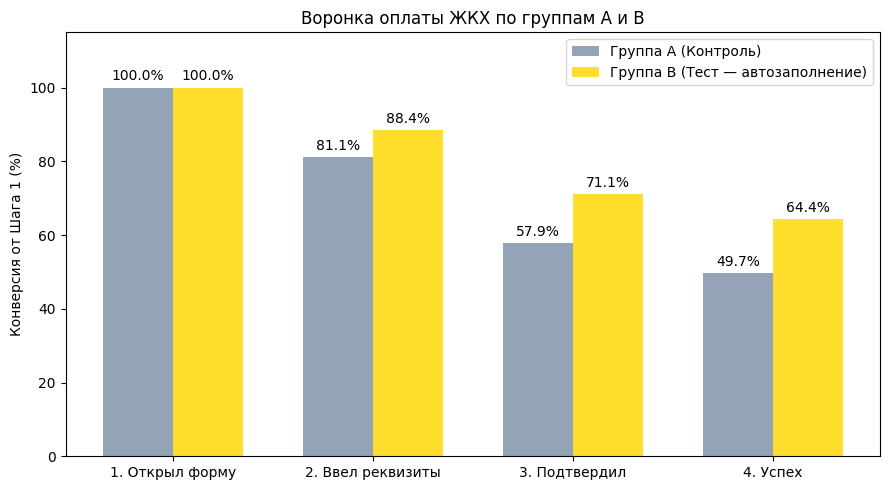

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width/2, funnel_pct.loc['A'], width, label='Группа A (Контроль)', color='#94a3b8')
rects2 = ax.bar(x + width/2, funnel_pct.loc['B'], width, label='Группа B (Тест — автозаполнение)', color='#ffdd2d')
ax.set_ylabel('Конверсия от Шага 1 (%)')
ax.set_title('Воронка оплаты ЖКХ по группам A и B')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()
ax.bar_label(rects1, fmt='%.1f%%', padding=3)
ax.bar_label(rects2, fmt='%.1f%%', padding=3)
plt.ylim(0, 115)
plt.tight_layout()
plt.show()

In [ ]:
z_pay, p_pay = proportions_ztest([870, 649], [1351, 1306])

z_user, p_user = proportions_ztest([603, 491], [750, 750])

clean_payments['is_success'] = clean_payments['step4_success'].notna().astype(int)
user_cr = clean_payments.groupby(['group', 'user_id'])['is_success'].mean()
t_stat, p_ttest = stats.ttest_ind(user_cr['B'], user_cr['A'], equal_var=False)

In [ ]:
print(z_pay, p_pay)
print(z_user, p_user)
print(user_cr)
print(t_stat)
print(p_ttest)

7.656876201474359 1.9051011652603112e-14
6.508665829737101 7.582117849078401e-11
group  user_id
A      1001       0.000000
       1002       0.000000
       1003       0.000000
       1004       0.666667
       1005       0.000000
                    ...   
B      2496       1.000000
       2497       0.000000
       2498       1.000000
       2499       1.000000
       2500       0.000000
Name: is_success, Length: 1500, dtype: float64
7.3311799360362375
3.726668558580098e-13
